# Fourier Transform -- Spatial Frequencies

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-02.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider

In [3]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Define parameters

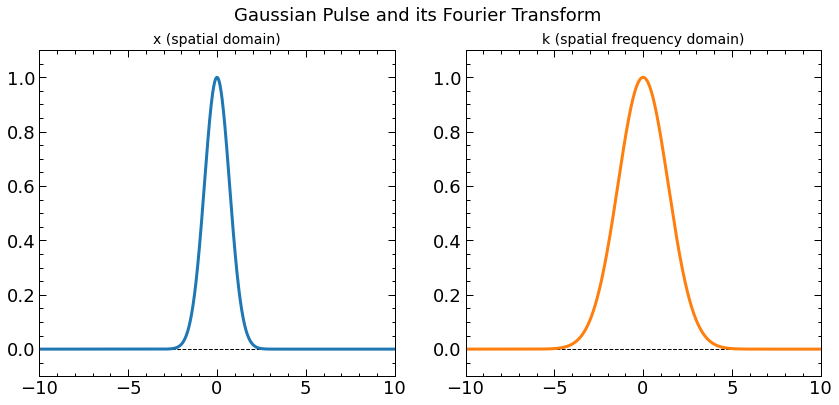

In [4]:
# Create domains for x (spatial) and k (frequency)
x1 = np.linspace(-10, 10, 1000)
k1 = np.linspace(-10, 10, 1000)

# width parameter 'a'
a1 = 1.0

# Define the functions
y1 = np.exp(- (a1**2) * (x1**2))
y2 = np.exp(- (k1**2) / (4 * a1**2))

# 2. Plot Setup
fig1, (ax11, ax12) = plt.subplots(1, 2, figsize=(14, 6))
# plt.subplots_adjust(bottom=0.25) # Leave space for slider
fig1.suptitle("Gaussian Pulse and its Fourier Transform", fontsize=18)

# --- Left Plot (Spatial Domain) ---
# We calculate the initial y-values

line1, = ax11.plot(x1, y1, linewidth=3, color='tab:blue')

ax11.set_title("x (spatial domain)", fontsize=14)
ax11.set_xlim(-10, 10)
ax11.set_ylim(-0.1, 1.1)
ax11.minorticks_on()
ax11.tick_params(which='both',direction="in",width=1)
ax11.tick_params(which='major',length=7)
ax11.tick_params(which='minor',length=3.5)
ax11.xaxis.set_ticks_position('both')
ax11.yaxis.set_ticks_position('both')
ax11.axhline(0, color='black', linewidth=1, linestyle='--', zorder=0)

# --- Right Plot (Frequency Domain) ---
line2, = ax12.plot(k1, y2, linewidth=3, color='tab:orange')

ax12.set_title("k (spatial frequency domain)", fontsize=14)
ax12.set_xlim(-10, 10)
ax12.set_ylim(-0.1, 1.1)
ax12.minorticks_on()
ax12.tick_params(which='both',direction="in",width=1)
ax12.tick_params(which='major',length=7)
ax12.tick_params(which='minor',length=3.5)
ax12.xaxis.set_ticks_position('both')
ax12.yaxis.set_ticks_position('both')
ax12.axhline(0, color='black', linewidth=1, linestyle='--', zorder=0)

plt.show()

## Add Slider

In [ ]:
%matplotlib widget

# 1. Setup Data
# Create domains for x (spatial) and k (frequency)
x1 = np.linspace(-10, 10, 1000)
k1 = np.linspace(-10, 10, 1000)

# Initial parameter 'a'
a_init = 1.0

# Define the functions
def gaussian_spatial(x, a):
    return np.exp(- (a**2) * (x**2))

def gaussian_frequency(k, a):
    return np.exp(- (k**2) / (4 * a**2))

# 2. Plot Setup
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
plt.subplots_adjust(bottom=0.25) # Leave space for slider
fig.suptitle("Gaussian Pulse and its Fourier Transform", fontsize=18)
fig.canvas.header_visible = False
fig.canvas.footer_visible = False

# --- Left Plot (Spatial Domain) ---
# We calculate the initial y-values
y1 = gaussian_spatial(x1, a_init)
line1, = ax1.plot(x1, y1, linewidth=3, color='tab:blue')

ax1.set_title("x (spatial domain)", fontsize=14)
ax1.set_xlim(-10, 10)
ax1.set_ylim(-0.1, 1.1) # Matches Mathematica {0, 1} with slight padding
ax1.minorticks_on()
ax1.tick_params(which='both',direction="in",width=1)
ax1.tick_params(which='major',length=7)
ax1.tick_params(which='minor',length=3.5)
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')
ax1.axhline(0, color='black', linewidth=1, linestyle='--', zorder=0)

# --- Right Plot (Frequency Domain) ---
y2 = gaussian_frequency(k1, a_init)
line2, = ax2.plot(k1, y2, linewidth=3, color='tab:orange')

ax2.set_title("k (spatial frequency domain)", fontsize=14)
ax2.set_xlim(-10, 10)
ax2.set_ylim(-0.1, 1.1) # Matches Mathematica {-0.25, 1}
ax2.minorticks_on()
ax2.tick_params(which='both',direction="in",width=1)
ax2.tick_params(which='major',length=7)
ax2.tick_params(which='minor',length=3.5)
ax2.xaxis.set_ticks_position('both')
ax2.yaxis.set_ticks_position('both')
ax2.axhline(0, color='black', linewidth=1, linestyle='--', zorder=0)

# 3. Slider Setup
ax_slider = plt.axes([0.25, 0.1, 0.5, 0.03])
slider = Slider(
    ax=ax_slider,
    label='Parameter a',
    valmin=0.01,
    valmax=10.0,
    valinit=a_init,
    valstep=0.01
)

# 4. Update Function
def update(val):
    a = slider.val
    
    # Recalculate y values based on new 'a'
    new_y1 = gaussian_spatial(x1, a)
    new_y2 = gaussian_frequency(k1, a)
    
    # Update the lines
    line1.set_ydata(new_y1)
    line2.set_ydata(new_y2)
    
    fig.canvas.draw_idle()

# Connect slider to update function
slider.on_changed(update)

plt.show()

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch05/ch05-02_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-02.html) (direct link: [ch05-02_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch05/ch05-02_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.